In [1]:
import pandas as pd

URL = 'https://storage.data.gov.my/finsector/exr/daily_1200.parquet'
fx = pd.read_parquet(URL)

print(fx.shape)
print(fx.columns.tolist())
print(fx['rate_type'].unique())
fx.head()

(18838, 29)
['date', 'rate_type', 'USD', 'EUR', 'JPY', 'GBP', 'SGD', 'AUD', 'CAD', 'CNY', 'CHF', 'THB', 'IDR', 'VND', 'KHR', 'MMK', 'PHP', 'BND', 'KRW', 'HKD', 'TWD', 'INR', 'PKR', 'NPR', 'SAR', 'AED', 'EGP', 'NZD', 'XDR']
<ArrowStringArray>
['middle', 'buying', 'selling']
Length: 3, dtype: str


,date,rate_type,USD,EUR,JPY,GBP,SGD,AUD,CAD,CNY,...,HKD,TWD,INR,PKR,NPR,SAR,AED,EGP,NZD,XDR
0,1997-01-02,middle,2.5265,NaN,0.021792,4.3188,1.8059,NaN,NaN,NaN,...,0.3267,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.6385
1,1997-01-03,middle,2.5245,NaN,0.021867,4.2765,1.8039,NaN,NaN,NaN,...,0.3264,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.6318
2,1997-01-06,middle,2.5205,NaN,0.021607,4.2637,1.7946,NaN,NaN,NaN,...,0.3258,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.6109
3,1997-01-07,middle,2.5000,NaN,0.021710,4.2338,1.7800,NaN,NaN,NaN,...,0.3231,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.5874
4,1997-01-08,middle,2.4913,NaN,0.021592,4.2238,1.7757,NaN,NaN,NaN,...,0.3220,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.5662


In [2]:
fx.to_parquet('fx_raw.parquet')
print('Saved!')

Saved!


In [ ]:
usd = fx[fx['rate_type'] == 'middle'][['date', 'USD']].copy() 
usd['date'] = pd.to_datetime(usd['date'])
usd = usd.set_index('date').sort_index()

usd = usd[usd.index >= '2005-07-22']

print(usd.shape)
print(usd.isna().sum())
print(usd.index.min(), 'to', usd.index.max())
usd.head()

(5222, 1)
USD    0
dtype: int64
2005-07-22 00:00:00 to 2026-10-23 00:00:00


,USD
date,
2005-07-22,3.7825
2005-07-25,3.7605
2005-07-26,3.7510
2005-07-27,3.7505
2005-07-28,3.7495


count    5222.000000
mean        3.827605
std         0.508276
min         2.938500
25%         3.332625
50%         3.944500
75%         4.218000
max         4.793500
Name: USD, dtype: float64


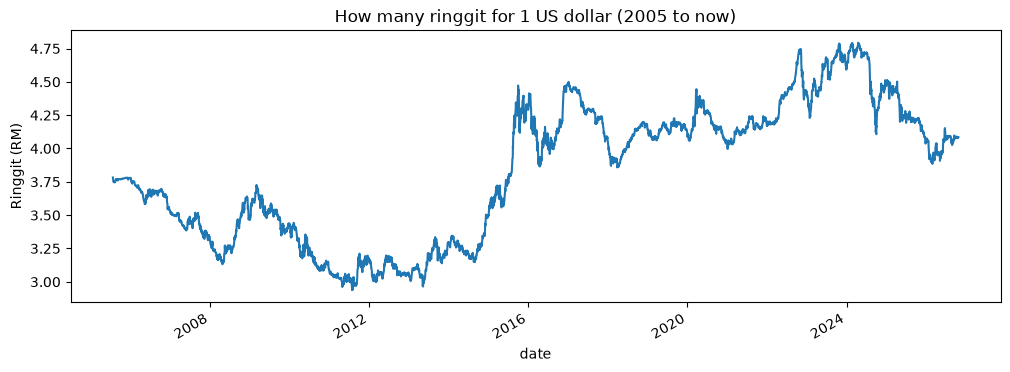

In [4]:
import matplotlib.pyplot as plt

print(usd['USD'].describe())

usd['USD'].plot(figsize=(12, 4))
plt.title('How many ringgit for 1 US dollar (2005 to now)')
plt.ylabel('Ringgit (RM)')
plt.show()

In [5]:
OIL_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=DCOILBRENTEU'
oil = pd.read_csv(OIL_URL)

oil.columns = ['date', 'Brent']
oil['date'] = pd.to_datetime(oil['date'])
oil['Brent'] = pd.to_numeric(oil['Brent'], errors='coerce')
oil = oil.set_index('date').sort_index()

oil.to_csv('oil_raw.csv')

print(oil.shape)
print(oil.isna().sum())
print(oil.index.min(), 'to', oil.index.max())
oil.tail()

(10285, 1)
Brent    1173
dtype: int64
1987-05-20 00:00:00 to 2026-10-20 00:00:00


,Brent
date,
2026-10-14,126.55
2026-10-15,126.35
2026-10-16,119.33
2026-10-19,118.82
2026-10-20,115.22


In [6]:
empty_days = oil[oil['Brent'].isna()]
print(empty_days.index.day_name().value_counts())

date
Monday       321
Friday       243
Tuesday      220
Wednesday    200
Thursday     189
Name: count, dtype: int64
